In [1]:
%pip install -q -r requirements-training.txt


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import torch

# Arbeitsverzeichnis neben dem Notebook. Hier landen Daten und Checkpoints;
# importiert wird von hier nichts, alles Wesentliche steht im Notebook selbst.
# WORK = Path.cwd() / "guppy"
WORK = Path.cwd()
(WORK / "Checkpoints").mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

# Ausgangspunkt für den Kurs; Laufzeit und Qualität hängen von Hardware und Daten ab.
# Für die Kursplanung auf dem Zielgerät messen.
MAX_STEPS = 6000

print(f"PyTorch {torch.__version__}")
print(f"Arbeitsverzeichnis: {WORK}")
print(f"Device: {DEVICE}, Schritte: {MAX_STEPS}")

from dataclasses import dataclass, asdict, replace

@dataclass
class GuppyConfig:
    vocab_size: int = 4096    # Anzahl unterschiedlicher Tokens im Vokabular
    max_seq_len: int = 128    # Maximale Kontextlänge in Tokens
    d_model: int = 384        # Embeddingdimension und Breite des Residualstroms
    n_layers: int = 6         # Anzahl der Blöcke
    n_heads: int = 6          # Attention-Köpfe je Block
    ffn_hidden: int = 1536    # innere Breite des FFN (4 x d_model)
    dropout: float = 0.1      # Regularisierung im Training; bei model.eval() abgeschaltet
    pad_id: int = 0           # Token-ID von <pad> - das ist Fülltoken für batches.
    bos_id: int = 1           # <|im_start|> , beginning-of-sequence
    eos_id: int = 2           # <|im_end|> , end-of-sequence

    def __post_init__(self):
        # Diese Bedingung ist beim Experimentieren mit der Kopfzahl wichtig.
        if self.d_model % self.n_heads:
            raise ValueError("d_model muss durch n_heads teilbar sein.")

# Gemeinsame Architekturwerte: hier vor der Datenaufbereitung ändern.
GRUNDKONFIG = GuppyConfig()


PyTorch 2.14.1
Arbeitsverzeichnis: /Users/thomasjorg/Documents/05_VSCode/DQR6_Material/M2a_Transformer
Device: mps, Schritte: 6000


In [3]:
import json


def lade_texte(dateipfad):
    texte = []
    with open(dateipfad, encoding="utf-8") as datei:
        for zeile in datei:
            beispiel = json.loads(zeile)
            texte.append(beispiel["text"])
    return texte


texte = {
    "train": lade_texte(WORK / "Data" / "train.jsonl"),
    "test": lade_texte(WORK / "Data" / "eval.jsonl"),
}

print(f"Training: {len(texte['train']):,} Beispiele")
print(f"Evaluation: {len(texte['test']):,} Beispiele")

Training: 57,000 Beispiele
Evaluation: 3,000 Beispiele


In [4]:
print("Ein lokal geladenes Trainingsbeispiel im ChatML-Format:\n")
print(texte["train"][0])

Ein lokal geladenes Trainingsbeispiel im ChatML-Format:

<|im_start|>user
what about a tankmate<|im_end|>
<|im_start|>assistant
would it live along the glass wall. that's my spot.<|im_end|>


In [5]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors

tokenizer = Tokenizer(models.BPE())
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=GRUNDKONFIG.vocab_size,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    special_tokens=["<pad>", "<|im_start|>", "<|im_end|>"],
    min_frequency=2,
    show_progress=True,
)
tokenizer.train_from_iterator(texte["train"], trainer)
tokenizer.post_processor = processors.ByteLevel(trim_offsets=False)
tokenizer.save(str(WORK / "data" / "tokenizer.json"))

print(f"Vokabular: {tokenizer.get_vocab_size()} Tokens")

# Vokabular und Sondertoken-IDs stammen aus genau diesem Tokenizer.
konfig = replace(
    GRUNDKONFIG,
    vocab_size=tokenizer.get_vocab_size(),
    pad_id=tokenizer.token_to_id("<pad>"),
    bos_id=tokenizer.token_to_id("<|im_start|>"),
    eos_id=tokenizer.token_to_id("<|im_end|>"),
)

for text in ("hello guppy", "Quantenverschränkung", "Hello, café! 🐟"):
    assert tokenizer.decode(tokenizer.encode(text).ids) == text, text
print("Rückübersetzung einschließlich Großbuchstaben und UTF-8 geprüft.")





Vokabular: 2597 Tokens
Rückübersetzung einschließlich Großbuchstaben und UTF-8 geprüft.


In [6]:
probe = "guppy likes bubbles"
kodiert = tokenizer.encode(probe)

print(f"{probe!r}  ->  {len(kodiert.ids)} Tokens\n")
for tid, stueck in zip(kodiert.ids, kodiert.tokens):
    print(f"  {tid:5d}   {stueck!r}")

print("\nSondertokens:")
for name in ["<pad>", "<|im_start|>", "<|im_end|>"]:
    print(f"  {name:14s} -> ID {tokenizer.token_to_id(name)}")

print(f"\nZurueckuebersetzt: {tokenizer.decode(kodiert.ids)!r}")

'guppy likes bubbles'  ->  5 Tokens

    978   'guppy'
    311   'Ġli'
     77   'k'
    313   'es'
    481   'Ġbubbles'

Sondertokens:
  <pad>          -> ID 0
  <|im_start|>   -> ID 1
  <|im_end|>     -> ID 2

Zurueckuebersetzt: 'guppy likes bubbles'


    50%-Quantil:  27 Tokens
    95%-Quantil:  36 Tokens
    99%-Quantil:  43 Tokens
   100%-Quantil:  59 Tokens


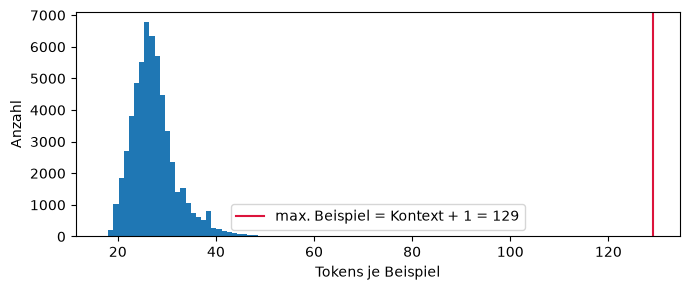

In [7]:
import matplotlib.pyplot as plt

laengen = sorted(len(tokenizer.encode(t).ids) for t in texte["train"])
for q in (0.5, 0.95, 0.99, 1.0):
    position = min(int(q * len(laengen)), len(laengen) - 1)
    print(f"  {q:5.0%}-Quantil: {laengen[position]:3d} Tokens")

plt.figure(figsize=(7, 3))
plt.hist(laengen, bins=40)
plt.axvline(konfig.max_seq_len + 1, color="crimson",
            label=f"max. Beispiel = Kontext + 1 = {konfig.max_seq_len + 1}")
plt.xlabel("Tokens je Beispiel")
plt.ylabel("Anzahl")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
def zu_sequenzen(liste, max_len):
    # Ein Beispiel benötigt L-1 Eingabepositionen. Deshalb sind L <= Kontext+1 zulässig.
    ergebnis = []
    for nummer, text in enumerate(liste):
        ids = tokenizer.encode(text).ids
        if len(ids) > max_len + 1:
            raise ValueError(
                f"Beispiel {nummer} hat {len(ids)} Tokens; für Kontext {max_len} "
                "sind höchstens max_seq_len + 1 zulässig. Kontext vergrößern "
                "oder die Daten bewusst aufbereiten; es wird nichts still abgeschnitten."
            )
        if len(ids) >= 2:
            ergebnis.append(ids)
    return ergebnis

train_seq = zu_sequenzen(texte["train"], konfig.max_seq_len)
eval_seq = zu_sequenzen(texte["test"], konfig.max_seq_len)
print(f"{len(train_seq):,} Trainings-, {len(eval_seq):,} Evaluationssequenzen")


def baue_batch(quelle, indizes, pad_id=None):
    """Baut aus Sequenz-Indizes einen rechts gepaddeten Batch (x, y)."""
    if pad_id is None:
        pad_id = konfig.pad_id
    sequenzen = [quelle[i] for i in indizes]
    batch_size = len(sequenzen)
    laenge = max(len(ids) - 1 for ids in sequenzen)
    x = torch.full((batch_size, laenge), pad_id, dtype=torch.long)
    y = torch.full((batch_size, laenge), pad_id, dtype=torch.long)

    for zeile, ids in enumerate(sequenzen):
        eingabe = torch.tensor(ids[:-1])
        ziel = torch.tensor(ids[1:])
        x[zeile, :len(eingabe)] = eingabe
        y[zeile, :len(ziel)] = ziel
    return x, y


57,000 Trainings-, 3,000 Evaluationssequenzen


In [9]:
x, y = baue_batch(train_seq, [0, 1, 2, 3])
print("Form:", tuple(x.shape), "\n")
print("x[0]:", x[0][:12].tolist())
print("y[0]:", y[0][:12].tolist())
print("\nals Text:")
print("  x:", repr(tokenizer.decode(x[0][:12].tolist(), skip_special_tokens=False)))
print("  y:", repr(tokenizer.decode(y[0][:12].tolist(), skip_special_tokens=False)))
print(f"\nPadding-Anteil in diesem Batch: {(y == konfig.pad_id).float().mean():.1%}")

Form: (4, 27) 

x[0]: [1, 281, 201, 355, 378, 276, 1191, 2, 201, 1, 282, 201]
y[0]: [281, 201, 355, 378, 276, 1191, 2, 201, 1, 282, 201, 989]

als Text:
  x: '<|im_start|>user\nwhat about a tankmate<|im_end|>\n<|im_start|>assistant\n'
  y: 'user\nwhat about a tankmate<|im_end|>\n<|im_start|>assistant\nwould'

Padding-Anteil in diesem Batch: 10.2%


In [10]:
# Die Konfiguration steht bereits vor der Datenaufbereitung fest.
print(konfig)
print(f"\nDimension je Kopf: {konfig.d_model} / {konfig.n_heads} = "
      f"{konfig.d_model // konfig.n_heads}")

GuppyConfig(vocab_size=2597, max_seq_len=128, d_model=384, n_layers=6, n_heads=6, ffn_hidden=1536, dropout=0.1, pad_id=0, bos_id=1, eos_id=2)

Dimension je Kopf: 384 / 6 = 64


In [11]:
import math
import torch.nn as nn
import torch.nn.functional as F


def kausale_maske(T, device=None):
    """Untere Dreiecksmatrix: Position i sieht nur 0..i."""
    return torch.tril(torch.ones(T, T, device=device)).view(1, 1, T, T)


class Attention(nn.Module):
    def __init__(self, konfig):
        super().__init__()
        self.n_heads = konfig.n_heads
        self.head_dim = konfig.d_model // konfig.n_heads
        self.qkv = nn.Linear(konfig.d_model, 3 * konfig.d_model)
        self.out = nn.Linear(konfig.d_model, konfig.d_model)
        self.dropout = nn.Dropout(konfig.dropout)

    def forward(self, x, maske=None, return_attn=False):
        B, T, C = x.shape

        # eine Matrixmultiplikation fuer Q, K und V zusammen, dann aufteilen
        qkv = self.qkv(x)
        qkv = qkv.reshape(B, T, 3, self.n_heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)      # je (B, Koepfe, T, head_dim)

        roh = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        if maske is not None:
            roh = roh.masked_fill(maske == 0, float("-inf"))
        gewichte = F.softmax(roh, dim=-1)          # (B, Koepfe, T, T)

        y = self.dropout(gewichte) @ v    # Values je Kopf gewichten
        y = y.transpose(1, 2)               # Tokenposition vor Kopfnummer
        y = y.contiguous().view(B, T, C)    # Köpfe wieder zusammenführen
        y = self.out(y)
        if return_attn:
            return y, gewichte
        return y

In [12]:
torch.manual_seed(0)
T, position = 6, 2

probe_attn = Attention(konfig).eval()
probe_x = torch.randn(1, T, konfig.d_model)
maske = kausale_maske(T)

print("Kausale Maske:")
print(maske[0, 0].to(torch.int).numpy())

_, ohne = probe_attn(probe_x, None,  return_attn=True)
_, mit  = probe_attn(probe_x, maske, return_attn=True)

print(f"\nEingabe {tuple(probe_x.shape)}  ->  Gewichte {tuple(mit.shape)}")
print("  (Batch, Koepfe, Ziel-Position, Quell-Position)\n")
print(f"Zeile {position} ohne Maske: {[round(w, 3) for w in ohne[0, 0, position].tolist()]}")
print(f"Zeile {position} mit  Maske: {[round(w, 3) for w in mit[0, 0, position].tolist()]}")
print(f"\nZeilensumme mit Maske: {mit[0, 0, position].sum():.4f}")

Kausale Maske:
[[1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 0 0]
 [1 1 1 1 0 0]
 [1 1 1 1 1 0]
 [1 1 1 1 1 1]]

Eingabe (1, 6, 384)  ->  Gewichte (1, 6, 6, 6)
  (Batch, Koepfe, Ziel-Position, Quell-Position)

Zeile 2 ohne Maske: [0.126, 0.207, 0.162, 0.239, 0.152, 0.115]
Zeile 2 mit  Maske: [0.254, 0.419, 0.327, 0.0, 0.0, 0.0]

Zeilensumme mit Maske: 1.0000


In [13]:
class FFN(nn.Module):
    def __init__(self, konfig):
        super().__init__()
        self.hoch   = nn.Linear(konfig.d_model, konfig.ffn_hidden)
        self.runter = nn.Linear(konfig.ffn_hidden, konfig.d_model)
        self.dropout = nn.Dropout(konfig.dropout)

    def forward(self, x):
        # tanh-Naeherung: exakt das, was GPT-2 als "gelu_new" rechnet
        x = self.hoch(x)
        x = F.gelu(x, approximate="tanh")
        x = self.runter(x)
        return self.dropout(x)


def zaehle(modul):
    return sum(p.numel() for p in modul.parameters())


print(f"FFN mit Faktor {konfig.ffn_hidden / konfig.d_model:.0f}: "
      f"{zaehle(FFN(konfig)):,} Parameter")
kleine_konfig = replace(konfig, ffn_hidden=2 * konfig.d_model)
kleines_ffn = FFN(kleine_konfig)
print(f"FFN mit Faktor 2: {zaehle(kleines_ffn):,} Parameter")

FFN mit Faktor 4: 1,181,568 Parameter
FFN mit Faktor 2: 590,976 Parameter


In [14]:
class Block(nn.Module):
    def __init__(self, konfig):
        super().__init__()
        self.norm1 = nn.LayerNorm(konfig.d_model)
        self.attn  = Attention(konfig)
        self.norm2 = nn.LayerNorm(konfig.d_model)
        self.ffn   = FFN(konfig)

    def forward(self, x, maske=None):
        x = x + self.attn(self.norm1(x), maske)   # Beitrag, kein Ersatz
        x = x + self.ffn(self.norm2(x))
        return x


torch.manual_seed(0)
probe_block = Block(konfig).eval()
with torch.no_grad():
    nachher = probe_block(probe_x, maske)

aenderung = (nachher - probe_x).norm() / probe_x.norm()
print(f"Norm des Residualstroms vorher : {probe_x.norm():.3f}")
print(f"Norm des Residualstroms nachher: {nachher.norm():.3f}")
print(f"relative Aenderung durch den Block: {aenderung:.1%}")
print(f"\nParameter je Block: {zaehle(probe_block):,}")

Norm des Residualstroms vorher : 48.449
Norm des Residualstroms nachher: 50.411
relative Aenderung durch den Block: 28.7%

Parameter je Block: 1,774,464


In [15]:
# Skalierungsfaktor alpha der Sinustabelle (Begründung im Markdown von 4.4).
# Unskaliert besteht jede Zeile aus d_model/2 Paaren (sin, cos) mit sin² + cos² = 1;
# der quadratische Mittelwert je Eintrag ist daher genau 1/2, der RMS 1/√2 ≈ 0,707.
# Mit alpha = 0,02·√2 hat jeder Eintrag den RMS 0,02 – dieselbe Größenordnung wie
# die mit Standardabweichung 0,02 initialisierten Token-Embeddings.
POS_ALPHA = 0.02 * math.sqrt(2)


def sinus_tabelle(max_len, d_model, alpha=POS_ALPHA):
    """Sinusförmige Positionskodierung nach Vaswani et al. (2017), mit alpha skaliert.

    Gerade Dimensionen erhalten den Sinus, ungerade den Kosinus derselben Frequenz.
    """
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)    # (max_len, 1)
    i = torch.arange(0, d_model, 2, dtype=torch.float32)                  # 0, 2, 4, ...
    winkel = position / (10000 ** (i / d_model))                          # (max_len, d_model/2)
    tabelle = torch.zeros(max_len, d_model)
    tabelle[:, 0::2] = torch.sin(winkel)
    tabelle[:, 1::2] = torch.cos(winkel)
    return alpha * tabelle


class GuppyLM(nn.Module):
    def __init__(self, konfig: GuppyConfig):
        super().__init__()
        self.konfig = konfig
        self.tok_emb = nn.Embedding(konfig.vocab_size, konfig.d_model)
        self.pos_emb = nn.Embedding(konfig.max_seq_len, konfig.d_model)
        self.drop = nn.Dropout(konfig.dropout)
        self.blocks = nn.ModuleList([Block(konfig) for _ in range(konfig.n_layers)])
        self.norm = nn.LayerNorm(konfig.d_model)
        self.lm_head = nn.Linear(konfig.d_model, konfig.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight     # dieselbe Matrix, nicht eine Kopie
        self.apply(self._init_gewichte)

        # Positionen: feste Tabelle statt gelernter Werte. pos_emb bleibt ein
        # nn.Embedding, damit Checkpointformat und Export unverändert bleiben;
        # die Tabelle wird nach der Initialisierung eingesetzt und eingefroren.
        with torch.no_grad():
            self.pos_emb.weight.copy_(sinus_tabelle(konfig.max_seq_len, konfig.d_model))
        self.pos_emb.weight.requires_grad_(False)

    def _init_gewichte(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, ziele=None):
        B, T = idx.shape
        if not 1 <= T <= self.konfig.max_seq_len:
            raise ValueError(f"Sequenzlänge {T} außerhalb des Kontexts {self.konfig.max_seq_len}.")
        pos = torch.arange(T, device=idx.device)
        token_embeddings = self.tok_emb(idx)
        positions_embeddings = self.pos_emb(pos)
        x = self.drop(token_embeddings + positions_embeddings)

        maske = kausale_maske(T, idx.device)
        for block in self.blocks:
            x = block(x, maske)

        logits = self.lm_head(self.norm(x))

        verlust = None
        if ziele is not None:
            verlust = F.cross_entropy(
                logits.view(-1, self.konfig.vocab_size),
                ziele.reshape(-1),
                ignore_index=self.konfig.pad_id,   # Padding zaehlt nicht
            )
        return logits, verlust

In [16]:
modell = GuppyLM(konfig)
gesamt = zaehle(modell)

print(f"{'Bauteil':<12}{'Parameter':>12}{'Anteil':>9}")
print("-" * 33)
for name, modul in [("tok_emb", modell.tok_emb), ("pos_emb", modell.pos_emb),
                    ("blocks", modell.blocks), ("norm", modell.norm)]:
    print(f"{name:<12}{zaehle(modul):>12,}{zaehle(modul)/gesamt:>9.1%}")
print("-" * 33)
print(f"{'gesamt':<12}{gesamt:>12,}{'':>9}")
trainierbar = sum(p.numel() for p in modell.parameters() if p.requires_grad)
print(f"{'trainierbar':<12}{trainierbar:>12,}{trainierbar/gesamt:>9.1%}")

print(f"\nOhne weight tying waeren es {gesamt + zaehle(modell.tok_emb):,} Parameter —")
print(f"die gemeinsame Matrix spart {zaehle(modell.tok_emb)/(gesamt+zaehle(modell.tok_emb)):.0%}.")

Bauteil        Parameter   Anteil
---------------------------------
tok_emb          997,248     8.5%
pos_emb           49,152     0.4%
blocks        10,646,784    91.0%
norm                 768     0.0%
---------------------------------
gesamt        11,693,952         
trainierbar   11,644,800    99.6%

Ohne weight tying waeren es 12,691,200 Parameter —
die gemeinsame Matrix spart 8%.


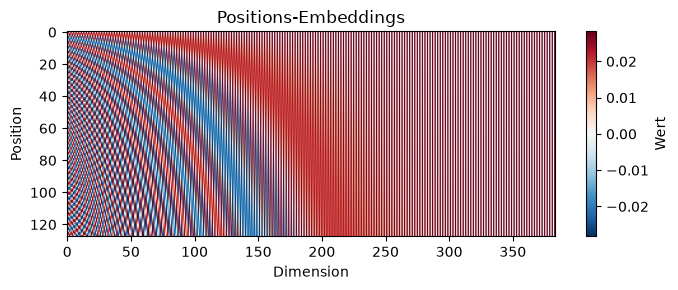

RMS je Eintrag: 0.0200, trainierbar: False


In [17]:
werte = modell.pos_emb.weight.detach().cpu()
grenze = werte.abs().max().item()

plt.figure(figsize=(7, 3))
plt.imshow(werte.numpy(), aspect="auto", cmap="RdBu_r", vmin=-grenze, vmax=grenze)
plt.colorbar(label="Wert")
plt.xlabel("Dimension")
plt.ylabel("Position")
plt.title("Positions-Embeddings")
plt.tight_layout()
plt.show()
print(f"RMS je Eintrag: {werte.pow(2).mean().sqrt():.4f}, "
      f"trainierbar: {modell.pos_emb.weight.requires_grad}")


In [18]:
modell.eval()
x_probe, y_probe = baue_batch(train_seq, list(range(8)))
with torch.no_grad():
    _, start_verlust = modell(x_probe, y_probe)

print(f"Verlust bei Zufallsgewichten: {start_verlust:.3f}")
print(f"ln(vocab_size)              : {math.log(konfig.vocab_size):.3f}")
print(f"Abweichung                  : {abs(start_verlust - math.log(konfig.vocab_size)):.3f}")

Verlust bei Zufallsgewichten: 7.975
ln(vocab_size)              : 7.862


Abweichung                  : 0.113


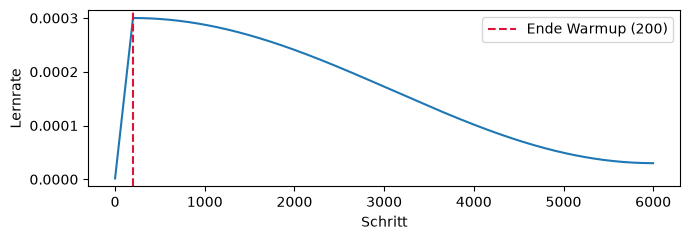

In [19]:
BATCH_SIZE   = 32
LR           = 3e-4
MIN_LR       = 3e-5
WARMUP       = 200
EVAL_ALLE    = 200
EVAL_BEISPIELE = 320
WEIGHT_DECAY = 0.1
GRAD_CLIP    = 1.0


def lernrate(schritt):
    if schritt < WARMUP:
        return LR * (schritt + 1) / WARMUP
    fortschritt = (schritt - WARMUP) / max(1, MAX_STEPS - WARMUP)
    return MIN_LR + (LR - MIN_LR) * 0.5 * (1 + math.cos(math.pi * fortschritt))


plt.figure(figsize=(7, 2.5))
plt.plot([lernrate(s) for s in range(MAX_STEPS)])
plt.axvline(WARMUP, color="crimson", ls="--", label=f"Ende Warmup ({WARMUP})")
plt.xlabel("Schritt")
plt.ylabel("Lernrate")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
import time

torch.manual_seed(42)

# Feste Validierungsstichprobe, begrenzt für einen kurzen Lehrlauf.
eval_batches = []
anzahl_eval = min(EVAL_BEISPIELE, len(eval_seq))
for start in range(0, anzahl_eval, BATCH_SIZE):
    indizes = list(range(start, min(start + BATCH_SIZE, anzahl_eval)))
    bx, by = baue_batch(eval_seq, indizes)
    eval_batches.append((bx.to(DEVICE), by.to(DEVICE)))
print(f"Validierung auf {anzahl_eval} Beispielen.")

Validierung auf 320 Beispielen.


In [21]:
@torch.no_grad()
def bewerte(modell):
    war_training = modell.training
    modell.eval()
    verlustsumme = 0.0
    tokenanzahl = 0
    for x, y in eval_batches:
        _, verlust = modell(x, y)
        gueltige_tokens = (y != modell.konfig.pad_id).sum().item()
        verlustsumme += verlust.item() * gueltige_tokens
        tokenanzahl += gueltige_tokens

    modell.train(war_training)
    return verlustsumme / tokenanzahl

In [22]:
# Tokenizer als Bestandteil jedes Checkpoints, nicht nur als separate Datei.
import hashlib
tokenizer_json = tokenizer.to_str()
tokenizer_sha256 = hashlib.sha256(tokenizer_json.encode("utf-8")).hexdigest()

modell = GuppyLM(konfig).to(DEVICE)
optimierer = torch.optim.AdamW(modell.parameters(), lr=LR,
                               weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
modell.train()

verlaufsverlust = []
eval_punkte = []
bester_eval = float("inf")
t0 = time.time()

print(f"{'Schritt':>8} | {'Lernrate':>9} | {'Train':>8} | {'Eval':>8} | {'Zeit':>7}")
print("-" * 52)

for schritt in range(MAX_STEPS):
    indizes = torch.randint(0, len(train_seq), (BATCH_SIZE,)).tolist()
    x, y = baue_batch(train_seq, indizes)
    x, y = x.to(DEVICE), y.to(DEVICE)

    lr = lernrate(schritt)
    for gruppe in optimierer.param_groups:
        gruppe["lr"] = lr

    _, verlust = modell(x, y)
    verlust.backward()
    torch.nn.utils.clip_grad_norm_(modell.parameters(), GRAD_CLIP)
    optimierer.step()
    optimierer.zero_grad(set_to_none=True)
    verlaufsverlust.append(verlust.item())

    if schritt % EVAL_ALLE == 0 or schritt == MAX_STEPS - 1:
        ev = bewerte(modell)
        eval_punkte.append((schritt, ev))
        letzte_verluste = verlaufsverlust[-EVAL_ALLE:]
        mittel = sum(letzte_verluste) / len(letzte_verluste)
        print(f"{schritt:8d} | {lr:9.6f} | {mittel:8.4f} | {ev:8.4f} | "
              f"{time.time()-t0:6.1f}s")
        if ev < bester_eval:
            bester_eval = ev
            checkpoint = {
                "schritt": schritt,
                "model_state_dict": modell.state_dict(),
                "konfig": asdict(konfig),
                "eval_verlust": ev,
                "tokenizer_json": tokenizer_json,
                "tokenizer_sha256": tokenizer_sha256,
            }
            torch.save(checkpoint, WORK / "checkpoints" / "bestes_modell_b.pt")

print(f"\nFertig in {time.time()-t0:.0f}s. Bester Eval-Verlust: {bester_eval:.4f}")

 Schritt |  Lernrate |    Train |     Eval |    Zeit
----------------------------------------------------
       0 |  0.000001 |   7.9085 |   7.8739 |    0.4s
     200 |  0.000300 |   4.1938 |   2.5924 |   12.5s
     400 |  0.000299 |   2.1339 |   1.5734 |   23.9s
     600 |  0.000297 |   1.3895 |   1.0129 |   35.2s
     800 |  0.000293 |   0.9497 |   0.7130 |   46.4s
    1000 |  0.000288 |   0.7202 |   0.5821 |   57.7s
    1200 |  0.000281 |   0.6055 |   0.5101 |   68.9s
    1400 |  0.000272 |   0.5405 |   0.4849 |   80.1s
    1600 |  0.000263 |   0.5093 |   0.4783 |   91.3s
    1800 |  0.000252 |   0.4879 |   0.4540 |  102.4s
    2000 |  0.000241 |   0.4698 |   0.4512 |  113.6s
    2200 |  0.000228 |   0.4623 |   0.4383 |  124.8s
    2400 |  0.000215 |   0.4465 |   0.4336 |  136.1s
    2600 |  0.000201 |   0.4387 |   0.4262 |  147.3s
    2800 |  0.000187 |   0.4355 |   0.4252 |  158.3s
    3000 |  0.000172 |   0.4279 |   0.4158 |  169.5s
    3200 |  0.000158 |   0.4220 |   0.4223 |  

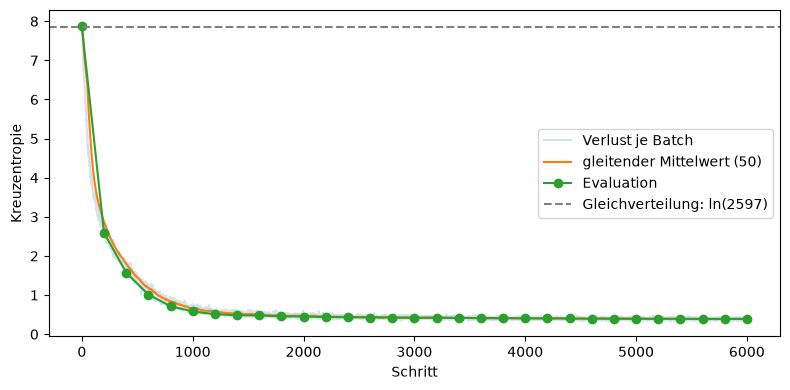

In [23]:
fenster = 50
geglaettet = []
for i in range(len(verlaufsverlust)):
    start = max(0, i - fenster + 1)
    ausschnitt = verlaufsverlust[start:i + 1]
    geglaettet.append(sum(ausschnitt) / len(ausschnitt))

plt.figure(figsize=(8, 4))
plt.plot(verlaufsverlust, alpha=0.2, label="Verlust je Batch")
plt.plot(geglaettet, label=f"gleitender Mittelwert ({fenster})")
plt.plot(*zip(*eval_punkte), "o-", label="Evaluation")
plt.axhline(math.log(konfig.vocab_size), color="gray", ls="--",
            label=f"Gleichverteilung: ln({konfig.vocab_size})")
plt.xlabel("Schritt")
plt.ylabel("Kreuzentropie")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
import hashlib
from tokenizers import Tokenizer


def lade_checkpoint(pfad, device):
    ckpt = torch.load(pfad, map_location="cpu", weights_only=True)
    if "tokenizer_json" not in ckpt or "tokenizer_sha256" not in ckpt:
        raise ValueError("Alter Checkpoint ohne zugeordneten Tokenizer. Bitte neu trainieren.")
    inhalt = ckpt["tokenizer_json"]
    pruefsumme = hashlib.sha256(inhalt.encode("utf-8")).hexdigest()
    if pruefsumme != ckpt["tokenizer_sha256"]:
        raise ValueError("Tokenizer-Prüfsumme im Checkpoint stimmt nicht.")
    tok = Tokenizer.from_str(inhalt)
    cfg = GuppyConfig(**ckpt["konfig"])
    if tok.get_vocab_size() != cfg.vocab_size:
        raise ValueError("Tokenizer und Modell haben verschiedene Vokabulargrößen.")
    sondertokens = {
        "<pad>": cfg.pad_id,
        "<|im_start|>": cfg.bos_id,
        "<|im_end|>": cfg.eos_id,
    }
    for name, token_id in sondertokens.items():
        if tok.token_to_id(name) != token_id:
            raise ValueError(f"Sondertoken {name} passt nicht zur Modellkonfiguration.")
    netz = GuppyLM(cfg).to(device)
    netz.load_state_dict(ckpt["model_state_dict"])
    netz.eval()
    return netz, tok, ckpt


modell, tokenizer, ckpt = lade_checkpoint(WORK / "checkpoints" / "bestes_modell_b.pt", DEVICE)
print(f"Für die Antworttests: bester Checkpoint aus Schritt {ckpt['schritt']}, "
      f"{sum(p.numel() for p in modell.parameters()):,} Parameter.")


Für die Antworttests: bester Checkpoint aus Schritt 5800, 11,693,952 Parameter.


In [25]:
import warnings


@torch.no_grad()
def erzeuge(modell, ids, max_neu=64, temperatur=0.7, top_k=50, return_info=False):
    """Generiert innerhalb des Kontextfensters; optional mit Abbruchgrund."""
    if not math.isfinite(temperatur) or temperatur < 0:
        raise ValueError("Die Temperatur muss endlich und mindestens 0 sein.")
    if not isinstance(max_neu, int) or max_neu < 0:
        raise ValueError("max_neu muss eine nichtnegative ganze Zahl sein.")
    if top_k is not None and (not isinstance(top_k, int) or top_k < 0):
        raise ValueError("top_k muss None oder eine nichtnegative ganze Zahl sein.")
    if not ids or len(ids) > modell.konfig.max_seq_len:
        raise ValueError(f"Der Prompt benötigt 1 bis {modell.konfig.max_seq_len} Tokens.")
    modell.eval()
    device = next(modell.parameters()).device
    idx = torch.tensor([ids], dtype=torch.long, device=device)
    grund = "Tokenlimit"

    for _ in range(max_neu):
        if idx.size(1) >= modell.konfig.max_seq_len:
            grund = "Kontextgrenze"
            break
        logits = modell(idx)[0][:, -1, :].clone()
        # Eine einzelne Assistant-Antwort enthält weder Padding noch einen Rollenstart.
        logits[:, [modell.konfig.pad_id, modell.konfig.bos_id]] = float("-inf")
        if temperatur == 0:
            naechstes = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperatur
            if top_k:
                k = min(top_k, logits.size(-1))
                top_werte = torch.topk(logits, k).values
                grenze = top_werte[:, -1:]
                logits = logits.masked_fill(logits < grenze, float("-inf"))
            wahrscheinlichkeiten = F.softmax(logits, dim=-1)
            naechstes = torch.multinomial(wahrscheinlichkeiten, num_samples=1)
        idx = torch.cat([idx, naechstes], dim=1)
        if naechstes.item() == modell.konfig.eos_id:
            grund = "Endtoken"
            break

    if grund == "Kontextgrenze" and not return_info:
        warnings.warn("Generierung an der Kontextgrenze beendet; nichts wurde abgeschnitten.")
    ergebnis = idx[0].tolist()
    return (ergebnis, grund) if return_info else ergebnis


def antworte(frage, temperatur=0.7, max_neu=64, top_k=50, return_info=False):
    prompt = f"<|im_start|>user\n{frage}<|im_end|>\n<|im_start|>assistant\n"
    ids = tokenizer.encode(prompt).ids
    alle, grund = erzeuge(modell, ids, max_neu, temperatur, top_k, return_info=True)
    text = tokenizer.decode(alle[len(ids):], skip_special_tokens=True).strip()
    if grund == "Kontextgrenze" and not return_info:
        warnings.warn("Antwort an der Kontextgrenze beendet.")
    return (text, grund) if return_info else text


In [26]:
frage = "hello guppy"
for temperatur in (0.0, 0.1, 0.7, 1.5):
    print(f"T = {temperatur}:")
    for _ in range(2):
        text, grund = antworte(frage, temperatur=temperatur, return_info=True)
        print(f"    {text} [{grund}]")

T = 0.0:
    hi there. i just found a nice spot in my favorite spot. [Endtoken]
    hi there. i just found a nice spot in my favorite spot. [Endtoken]
T = 0.1:
    hi there. i just found a nice spot near the bottom. [Endtoken]
    hi there. i just found a nice spot in my favorite spot. [Endtoken]
T = 0.7:
    hi there. did you bring the red flakes. [Endtoken]
    hi there. i just found a nice spot near the bottom. [Endtoken]
T = 1.5:
    hi there. did you bring freeze dried worms. the bubbles feels nice. [Endtoken]
    hi there. i was thinking about freeze dried worms. i blew some bubbles earlier. [Endtoken]


In [27]:
fragen = [
    "hello guppy", "are you hungry", "it's very hot today",
    "how is the water", "do you like bubbles", "what is the internet",
    "do you sometimes feel lonely", "the cat is watching you",
    "tell me a joke", "what do you dream about",
    "what is the meaning of life", "goodnight guppy",
]

for frage in fragen:
    text, grund = antworte(frage, return_info=True)
    print(f"{frage:<30} -> {text} [{grund}]")


hello guppy                    -> hi there. i didn't see you there. my eyes are on the sides. the coolness feels nice. [Endtoken]
are you hungry                 -> is it food time. please say yes. food is my favorite thing after water. i'll eat it in my favorite spot. [Endtoken]
it's very hot today            -> when it's warm i breathe harder. i am small and i overheat easy. [Endtoken]
how is the water               -> the water around the sand feels just right. i'll swim around between the rocks to feel the new water. water is life for me. [Endtoken]
do you like bubbles            -> the bubbles are back. my tail get bubbly when i swim through them. [Endtoken]
what is the internet           -> the water feels warmer than usual. i just sit at the bottom and breathe heavy. can you do something about it. [Endtoken]
do you sometimes feel lonely   -> i'm used to being the only one in here. i wouldn't say no to a snail though. [Endtoken]
the cat is watching you        -> is it friendly. it

In [28]:
modell, tokenizer, ckpt = lade_checkpoint(WORK / "checkpoints" / "bestes_modell_b.pt", DEVICE)
print(f"Geladen aus Schritt {ckpt['schritt']}: {zaehle(modell):,} Parameter")
print(f"Checkpoint: {WORK / 'checkpoints' / 'bestes_modell_b.pt'}")
text, grund = antworte("hello guppy", temperatur=0, return_info=True)
print(f"\nProbe: {text} [{grund}]")

Geladen aus Schritt 5800: 11,693,952 Parameter
Checkpoint: /Users/thomasjorg/Documents/05_VSCode/DQR6_Material/M2a_Transformer/checkpoints/bestes_modell_b.pt

Probe: hi there. i just found a nice spot in my favorite spot. [Endtoken]
